In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

folder_path = '/content/drive/MyDrive/Lab2_Computational_Intelligence'
part3_path = folder_path + '/Part3_Depth_Estimation'

for name in ['images']:
    os.makedirs(part3_path + '/' + name, exist_ok=True)

***Real Distance Measurements***

In [ ]:
real_distances = {
    'image1': [0.615, 0.640, 0.620, 0.694, 0.835, 1.200],
    'image2': [0.462, 0.900, 0.342, 0.474, 0.630, 0.880],
    'image3': [0.683, 0.542, 0.860, 0.712, 0.580, 0.496]
}

objects = ['Can', 'Duck', 'Lip balm', 'Figure toy', 'Bottle', 'Box']

In [ ]:
!pip install -q -U transformers accelerate

***Depth Anything V2***

In [ ]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

model = pipeline(
    'depth-estimation',
    model='depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf',
    device=device
)

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

***Generating the three depth maps***

Images found: ['image_1.jpg', 'image_2.jpg', 'image_3.jpg']


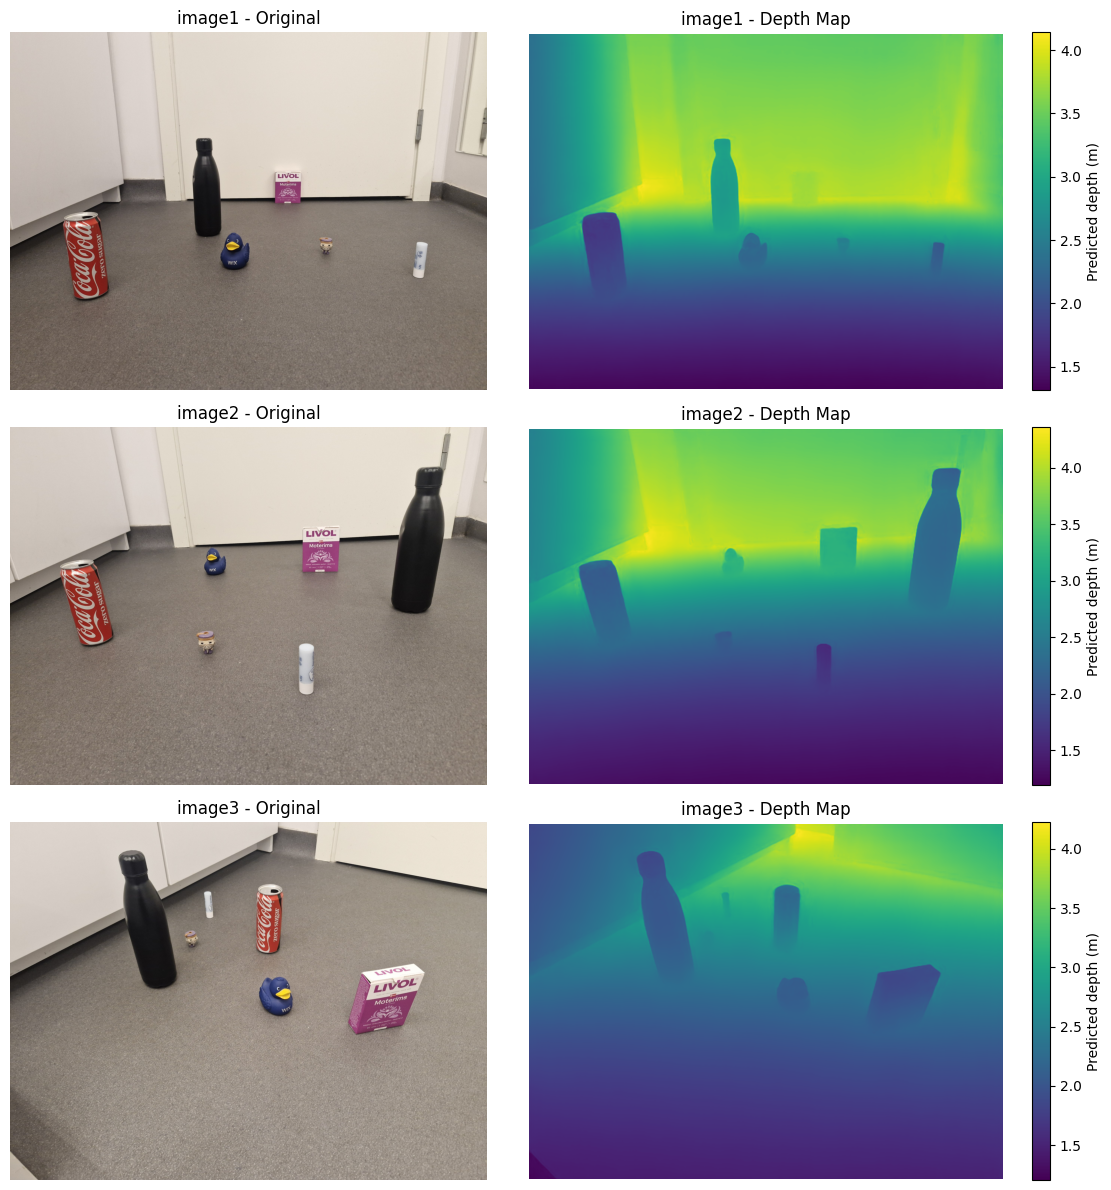

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

image_folder = part3_path + '/images'

files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print("Images found:", files)

depth_maps = {}

plt.figure(figsize=(12, 12))

for i, filename in enumerate(files[:3]):
    image = Image.open(image_folder + '/' + filename).convert('RGB')

    result = model(image)
    depth = result['predicted_depth'].squeeze().cpu().numpy()

    name = f'image{i+1}'
    depth_maps[name] = depth

    plt.subplot(3, 2, i * 2 + 1)
    plt.imshow(image)
    plt.title(name + ' - Original')
    plt.axis('off')

    plt.subplot(3, 2, i * 2 + 2)
    plt.imshow(depth, cmap='viridis')
    plt.colorbar(label='Predicted depth (m)')
    plt.title(name + ' - Depth Map')
    plt.axis('off')

plt.tight_layout()
plt.show()

***Select the object positions***

In [ ]:
objects = ['Can', 'Duck', 'Lip balm', 'Figure toy', 'Bottle', 'Box']

positions = {
    'image1': [(0.15, 0.62), (0.47, 0.61), (0.86, 0.64),
               (0.66, 0.60), (0.41, 0.43), (0.58, 0.43)],

    'image2': [(0.16, 0.48), (0.43, 0.38), (0.62, 0.67),
               (0.41, 0.60), (0.85, 0.31), (0.65, 0.34)],

    'image3': [(0.54, 0.27), (0.56, 0.49), (0.42, 0.22),
               (0.38, 0.34), (0.28, 0.26), (0.78, 0.50)]
}

***Verify the object positions***

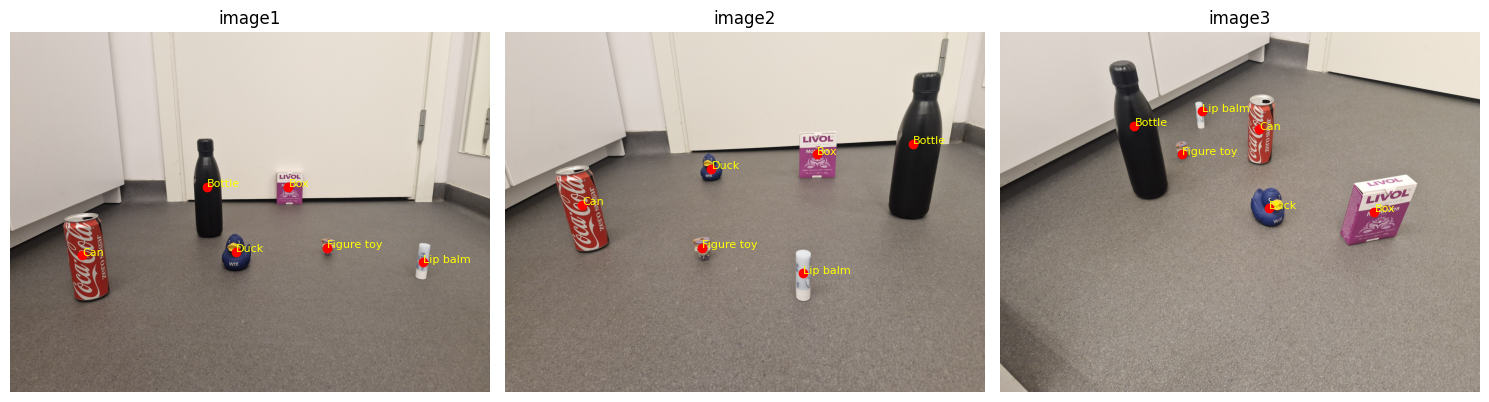

In [ ]:
plt.figure(figsize=(15, 5))

for i in range(3):
    name = f'image{i+1}'
    image = Image.open(image_folder + '/' + files[i])

    plt.subplot(1, 3, i + 1)
    plt.imshow(image)

    for obj, (x, y) in zip(objects, positions[name]):
        plt.plot(x * image.width, y * image.height, 'ro')
        plt.text(x * image.width, y * image.height, obj,
                 fontsize=8, color='yellow')

    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

***Calculate the estimated distances and errors***

In [ ]:
import numpy as np
import pandas as pd

results = []

for i in range(3):
    name = f'image{i+1}'
    depth = depth_maps[name]
    h, w = depth.shape

    predicted = []

    for x, y in positions[name]:
        px = int(x * (w - 1))
        py = int(y * (h - 1))

        # Median depth around the selected point
        value = np.median(depth[max(0, py-3):py+4,
                                max(0, px-3):px+4])
        predicted.append(value)

    # Bottle (index 4) is the reference
    scale = real_distances[name][4] / predicted[4]

    for j, obj in enumerate(objects):
        real = real_distances[name][j]
        estimated = predicted[j] * scale

        error = abs(real - estimated)
        error_percent = error / real * 100

        results.append([name, obj, real, predicted[j],
                        estimated, error, error_percent])

table = pd.DataFrame(results, columns=[
    'Image', 'Object', 'Real (m)', 'Raw depth (m)',
    'Estimated (m)', 'Error (m)', 'Error (%)'
])

display(table.round(3))

,Image,Object,Real (m),Raw depth (m),Estimated (m),Error (m),Error (%)
0,image1,Can,0.615,1.854,0.544,0.071,11.497000
1,image1,Duck,0.640,2.273,0.667,0.027,4.237000
2,image1,Lip balm,0.620,2.161,0.634,0.014,2.304000
3,image1,Figure toy,0.694,2.534,0.744,0.050,7.184000
4,image1,Bottle,0.835,2.845,0.835,0.000,0.000000
5,image1,Box,1.200,3.731,1.095,0.105,8.744000
6,image2,Can,0.462,2.145,0.599,0.137,29.673000
7,image2,Duck,0.900,3.253,0.908,0.008,0.933000
8,image2,Lip balm,0.342,1.664,0.465,0.123,35.860001
9,image2,Figure toy,0.474,2.098,0.586,0.112,23.615999


***Calculate the average error***

In [ ]:
# Exclude reference objects from evaluation
evaluation = table[table['Object'] != 'Bottle']

print("Average Absolute Error:",
      round(evaluation['Error (m)'].mean(), 3), "m")

print("Average Percentage Error:",
      round(evaluation['Error (%)'].mean(), 2), "%")

Average Absolute Error: 0.059 m
Average Percentage Error: 10.83 %


***Depth Estimation Results Visualization***

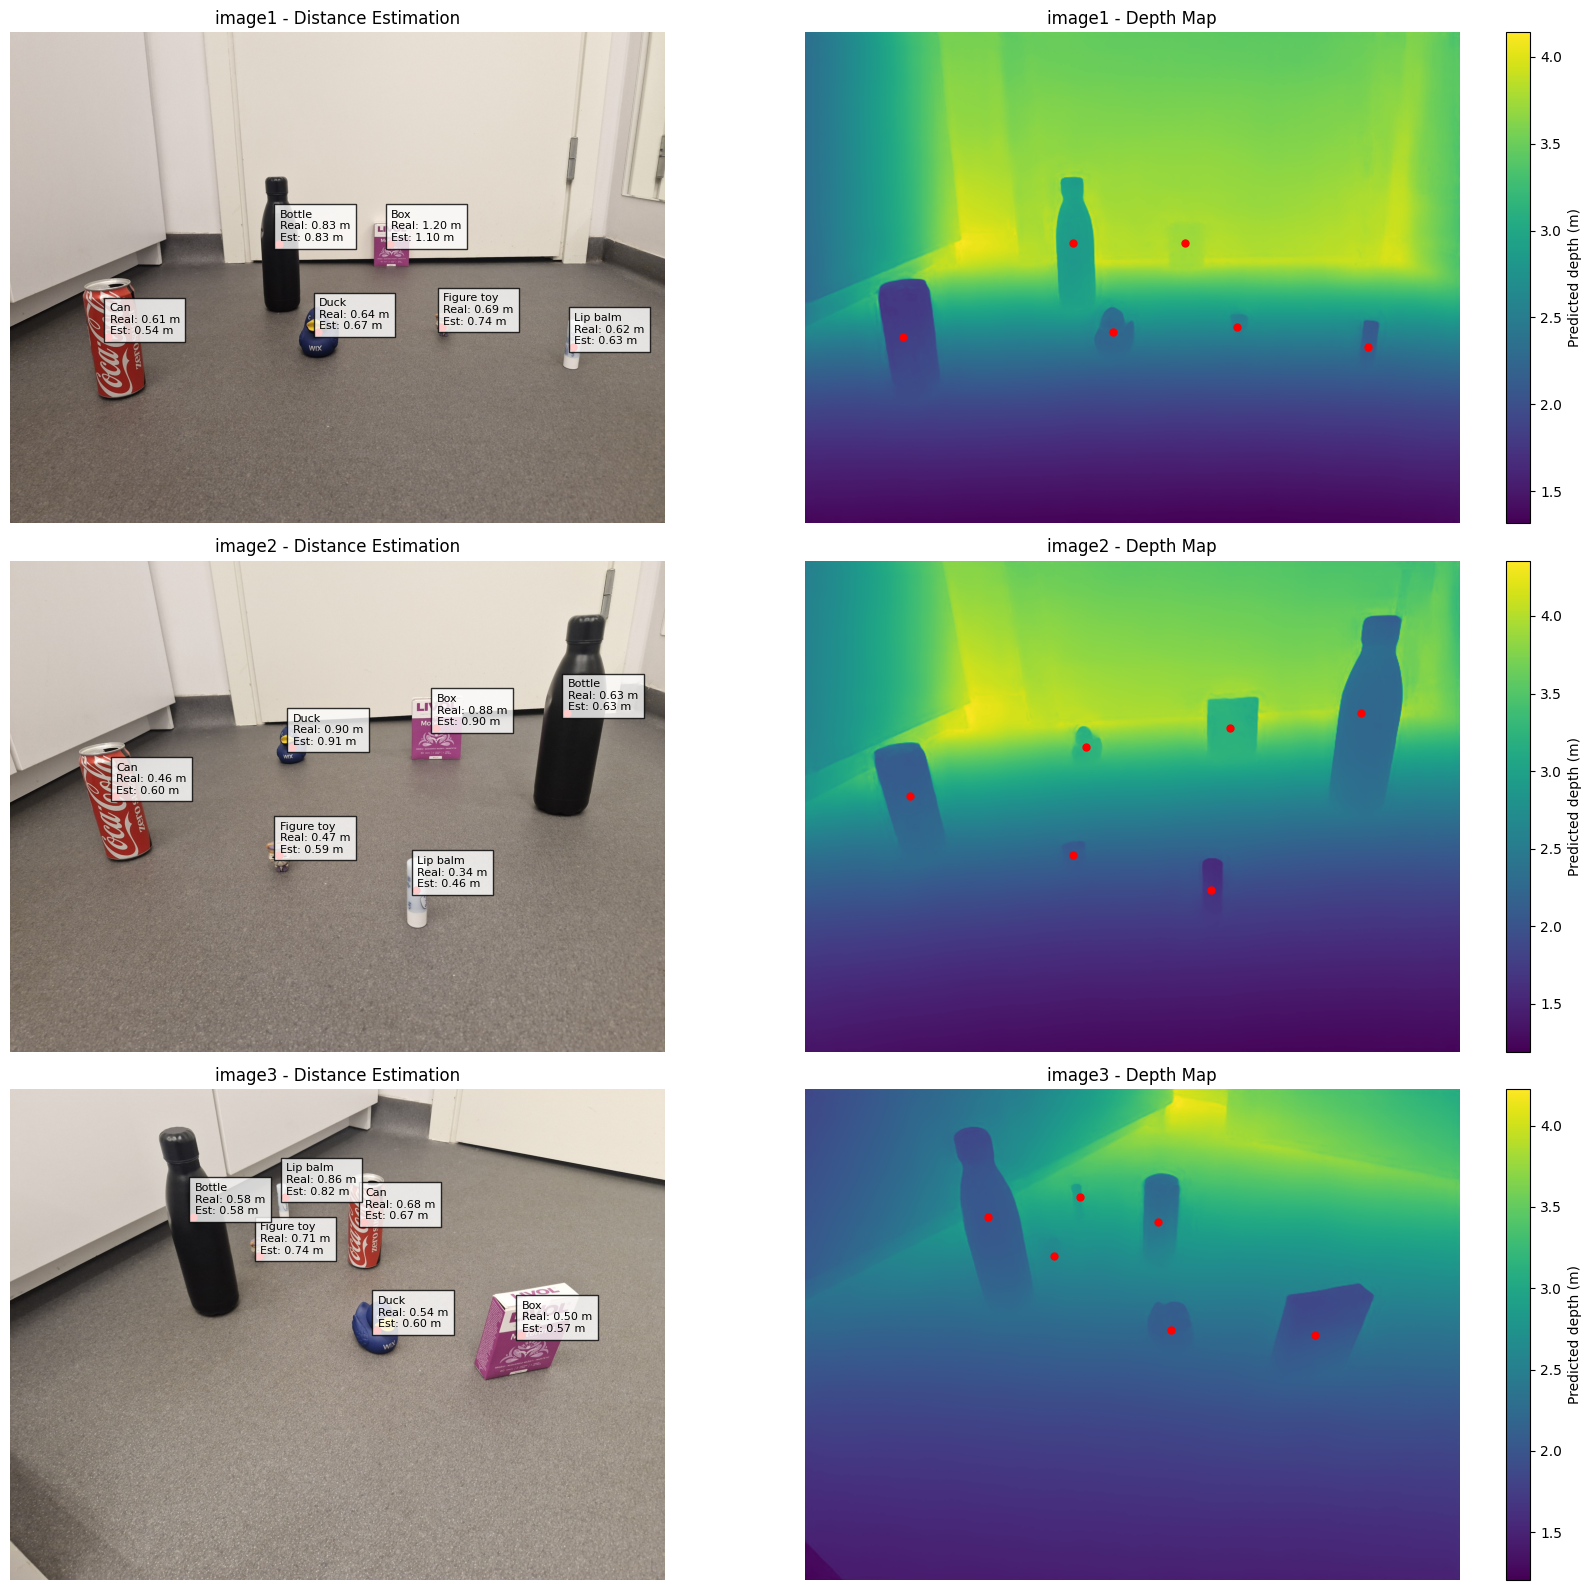

In [ ]:
plt.figure(figsize=(18, 16))

for i in range(3):
    name = f'image{i+1}'

    image = Image.open(image_folder + '/' + files[i])
    depth = depth_maps[name]

    # Original image with distances
    plt.subplot(3, 2, i * 2 + 1)
    plt.imshow(image)

    for j, (x, y) in enumerate(positions[name]):
        row = table[(table['Image'] == name) &
                    (table['Object'] == objects[j])].iloc[0]

        px = x * image.width
        py = y * image.height

        plt.plot(px, py, 'ro', markersize=5)

        plt.text(px + 5, py - 10,
                 f"{objects[j]}\n"
                 f"Real: {row['Real (m)']:.2f} m\n"
                 f"Est: {row['Estimated (m)']:.2f} m",
                 fontsize=8, color='black',
                 bbox=dict(facecolor='white', alpha=0.8))

    plt.title(name + ' - Distance Estimation')
    plt.axis('off')

    # Depth map
    plt.subplot(3, 2, i * 2 + 2)
    plt.imshow(depth, cmap='viridis')
    plt.colorbar(label='Predicted depth (m)')
    plt.title(name + ' - Depth Map')

    for x, y in positions[name]:
        plt.plot(x * (depth.shape[1] - 1),
                 y * (depth.shape[0] - 1), 'ro', markersize=5)

    plt.axis('off')

plt.tight_layout()
plt.show()

***Visualize estimation errors***

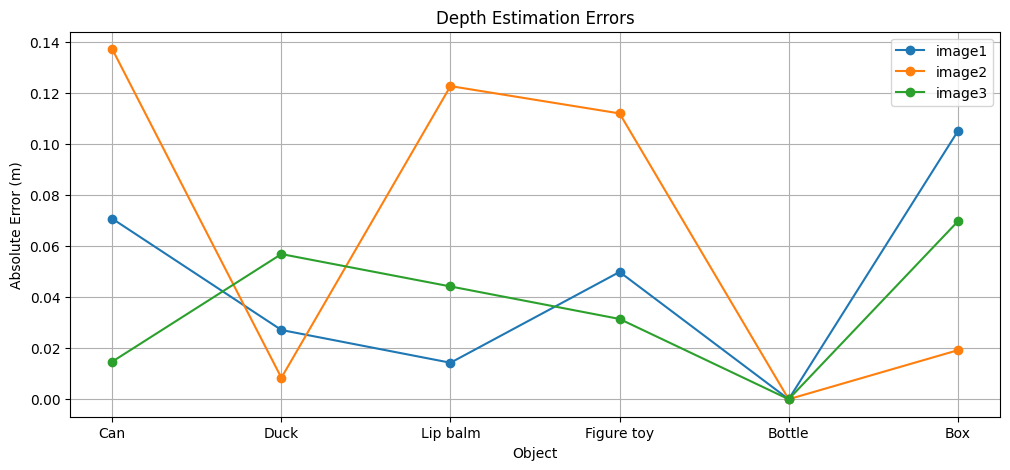

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for name in ['image1', 'image2', 'image3']:
    data = table[table['Image'] == name]
    plt.plot(data['Object'], data['Error (m)'],
             marker='o', label=name)

plt.xlabel('Object')
plt.ylabel('Absolute Error (m)')
plt.title('Depth Estimation Errors')
plt.legend()
plt.grid(True)
plt.show()

***Compare average errors***

In [ ]:
evaluation = table[table['Object'] != 'Bottle']

average_errors = evaluation.groupby('Image')[
    ['Error (m)', 'Error (%)']
].mean()

display(average_errors.round(3))

,Error (m),Error (%)
Image,,
image1,0.053,6.793
image2,0.080,18.452
image3,0.043,7.247
